# T39 -- Phase 3: visualization suite + old-vs-new ranking comparison

Extends (does not replace) `notebooks/main_actual_data_pipeline.ipynb`'s own
visualization cells -- reuses the SAME hotspot-heatmap panel pattern (its Section 9/
cell 31), the SAME observed-slick parcel plot (its Section 1), and T28's own
diagnostic-table function -- on the SAME cached real Stage III result the T27-T38
notebooks already used, extended to the full T27-T38 evidence chain.

**`source_score` remains an evidence-ranking score, NOT a probability. This notebook
does not modify T14-T38; every quantity plotted/tabulated below is read directly from
already-approved module output.**

In [1]:
import os, sys, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, QhullError

from iste.ensemble_run import EnsembleRunRecords
from iste.analysis_grid import generate_analysis_grid
from iste.candidate_extraction import CandidateExtractionConfig, find_candidate_peaks
from iste.kdtree_neighborhood import build_particle_neighborhood_index, project_to_local_metres
from iste.particle_query import query_particle_slice
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.phase3_composite import DEFAULT_WEIGHTS, compute_source_scores_for_candidates
from iste.phase3_clustering import DEFAULT_EPS_M, cluster_candidates
from iste.phase3_uncertainty import (
    DEFAULT_TOTAL_TIMESTAMPS, DEFAULT_SPATIAL_PERCENTILE, BootstrapConfig,
    compute_cluster_uncertainty_table, run_bootstrap_stability,
)
from iste.phase3_diagnostics import compute_diagnostics_table

## 1. Load real observation + Stage III result (identical source data to T27-T38)

In [2]:
spill_data = json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
parcels = spill["parcels"]
obs_lat = np.array([p["lat"] for p in parcels])
obs_lon = np.array([p["lon"] for p in parcels])
obs_conf = np.array([p["confidence"] for p in parcels])
obs_ref_lat, obs_ref_lon = float(np.mean(obs_lat)), float(np.mean(obs_lon))
print(f"observed slick: {spill['image_filename']}, {len(parcels)} parcels, "
      f"reference point (mean) = ({obs_ref_lat:.5f}, {obs_ref_lon:.5f})")

history_path = os.path.join(REPO_ROOT, "results", "actual_data", "stage3_particle_history.npz")
cached = np.load(history_path, allow_pickle=True)

def _none_if_empty(arr):
    return None if arr.size == 0 else arr

records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
t_obs = np.datetime64(np.max(records.timestamp), "ns")
grid = generate_analysis_grid(t_obs, window_hours=72.0, interval_hours=1.0)
historical_timestamps = grid[1:]
print(f"loaded {records.n_records} real rows; full analysis grid has {len(grid)} timestamps (T0..T72)")

observed slick: ow-0008.jpg, 548 parcels, reference point (mean) = (34.07660, 35.26621)
loaded 240024 real rows; full analysis grid has 73 timestamps (T0..T72)


## 2. Regenerate candidates + T36 scores + T37 clusters + T38 uncertainty
(identical setup to `T37_clustering_check.ipynb`/`T38_uncertainty_check.ipynb`;
also collects the valid-particle position envelope during the same sweep -- no extra
Stage III queries beyond what this sweep already performs.)

In [3]:
lat_min = min(spill["bounding_box"]["upper_left"]["lat"], spill["bounding_box"]["bottom_right"]["lat"], float(records.lat[records.valid].min()))
lat_max = max(spill["bounding_box"]["upper_left"]["lat"], spill["bounding_box"]["bottom_right"]["lat"], float(records.lat[records.valid].max()))
lon_min = min(spill["bounding_box"]["upper_left"]["lon"], spill["bounding_box"]["bottom_right"]["lon"], float(records.lon[records.valid].min()))
lon_max = max(spill["bounding_box"]["upper_left"]["lon"], spill["bounding_box"]["bottom_right"]["lon"], float(records.lon[records.valid].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)

t0 = time.time()
all_candidates = []
support_grids_by_t_s = {}
envelope_lat, envelope_lon = [], []
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    envelope_lat.append(slice_.lat[slice_.valid]); envelope_lon.append(slice_.lon[slice_.valid])
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(
        index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config,
    )
    grid_vals = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    support_grids_by_t_s[np.datetime64(t_s, "ns")] = grid_vals
    all_candidates.extend(find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config))
t1 = time.time()
envelope_lat = np.concatenate(envelope_lat); envelope_lon = np.concatenate(envelope_lon)
print(f"regenerated {len(all_candidates)} real candidates in {t1-t0:.1f}s; pooled {len(envelope_lat)} valid particle positions for the envelope")

regenerated 280 real candidates in 70.5s; pooled 236736 valid particle positions for the envelope


In [4]:
t2 = time.time()
default_scores = compute_source_scores_for_candidates(
    records, all_candidates, support_grids_by_t_s, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M,
    weights=DEFAULT_WEIGHTS,
)
clusters = cluster_candidates(all_candidates, default_scores, eps_m=DEFAULT_EPS_M)
t3 = time.time()
print(f"computed T36 scores + T37 clusters ({len(clusters)} clusters) in {t3-t2:.1f}s")

bootstrap_result = run_bootstrap_stability(
    all_candidates, default_scores, clusters, config=BootstrapConfig(n_replicates=200, random_seed=42, top_k=10),
)
uncertainty_table = compute_cluster_uncertainty_table(
    clusters, all_candidates, default_scores, records,
    total_timestamps=DEFAULT_TOTAL_TIMESTAMPS, spatial_percentile=DEFAULT_SPATIAL_PERCENTILE,
    bootstrap_result=bootstrap_result,
)
uncertainty_by_cluster = {r.cluster_id: r for r in uncertainty_table}
print(f"computed T38 uncertainty for {len(uncertainty_table)} clusters (bootstrap runtime {bootstrap_result.runtime_seconds:.2f}s)")

computed T36 scores + T37 clusters (10 clusters) in 39.2s


computed T38 uncertainty for 10 clusters (bootstrap runtime 2.92s)


## 3. Old-vs-new ranking comparison

**Old method (`T17-raw-support baseline`):** exactly the selection rule
`main_actual_data_pipeline.ipynb`'s own Section 10 already documents -- rank ALL
candidates by their raw T17 `support_score` (`Support(x,y,t) = f(D,W,V)`, the
un-normalized backward-KDE concentration at the candidate's own peak) descending, no
cross-timestamp correction of any kind.

**New method:** rank the SAME candidates by their T36 `source_score` (composite of
T29/T34 normalized support, T31 persistence, T32 convergence, T33 dispersion, T35 AIS
-- see `iste/phase3_composite.py`), computed once above, unmodified.

Table below: the UNION of the old-top-10 and new-top-10 candidate sets, so every
candidate that either method considered a leading candidate is visible, sorted by
`new_rank`.

In [5]:
from iste.phase3_persistence import track_candidate_persistence
tracks = track_candidate_persistence(all_candidates)
track_by_candidate_id = {}
for tr in tracks:
    for cid in tr.candidate_ids:
        track_by_candidate_id[cid] = tr

old_ranked = sorted(all_candidates, key=lambda c: -c.support_score)
old_rank_by_id = {c.candidate_id: i + 1 for i, c in enumerate(old_ranked)}

scores_by_id = {s.candidate_id: s for s in default_scores}
new_ranked = sorted(all_candidates, key=lambda c: -scores_by_id[c.candidate_id].source_score)
new_rank_by_id = {c.candidate_id: i + 1 for i, c in enumerate(new_ranked)}

old_top10_ids = {c.candidate_id for c in old_ranked[:10]}
new_top10_ids = {c.candidate_id for c in new_ranked[:10]}
union_ids = old_top10_ids | new_top10_ids
candidates_by_id = {c.candidate_id: c for c in all_candidates}

rows = []
for cid in union_ids:
    c = candidates_by_id[cid]
    s = scores_by_id[cid]
    track = track_by_candidate_id.get(cid)
    dist_x, dist_y = project_to_local_metres(c.y_peak, c.x_peak, lat_ref=obs_ref_lat, lon_ref=obs_ref_lon)
    dist_km = float(np.sqrt(dist_x[0]**2 + dist_y[0]**2)) / 1000.0
    rows.append(dict(
        candidate_id=cid,
        old_rank=old_rank_by_id[cid], new_rank=new_rank_by_id[cid],
        old_score=round(c.support_score, 4), new_score=round(s.source_score, 4),
        support_duration_hours=round(track.persistence_duration_hours, 1) if track is not None else 0.0,
        distance_from_observed_km=round(dist_km, 2),
        particle_support=int(c.density_score),
        AIS_support=("unavailable" if s.ais_evidence is None else round(s.ais_evidence, 4)),
        screening_support=round(s.support_evidence, 4),
    ))
comparison_df = pd.DataFrame(rows).sort_values("new_rank").reset_index(drop=True)
print(comparison_df.to_string(index=False))
comparison_df.to_csv(os.path.join(REPO_ROOT, "results", "actual_data", "T39_old_vs_new_ranking.csv"), index=False)

               candidate_id  old_rank  new_rank  old_score  new_score  support_duration_hours  distance_from_observed_km  particle_support AIS_support  screening_support
2019-10-11T23:00:00_cand000        72         1   855.3053     1.4620                    71.0                      36.48               340 unavailable             1.4662
2019-10-12T04:00:00_cand000        67         2   929.9753     1.4388                    71.0                      33.85               367 unavailable             1.5220
2019-10-12T00:00:00_cand000        71         3   861.4151     1.4355                    71.0                      35.88               339 unavailable             1.4524
2019-10-12T05:00:00_cand000        66         4   942.2044     1.4354                    71.0                      33.55               376 unavailable             1.5438
2019-10-12T01:00:00_cand000        68         5   875.9771     1.4275                    71.0                      34.92               336 unavailable

In [6]:
n_old_only = len(old_top10_ids - new_top10_ids)
n_new_only = len(new_top10_ids - old_top10_ids)
n_both = len(old_top10_ids & new_top10_ids)
print(f"old-top-10 candidates NOT in new-top-10: {n_old_only}")
print(f"new-top-10 candidates NOT in old-top-10: {n_new_only}")
print(f"candidates in BOTH top-10 sets: {n_both}")

old_top1 = old_ranked[0]
new_top1 = new_ranked[0]
print(f"old_rank=1 candidate: {old_top1.candidate_id} (t_s={old_top1.t_s}, support_score={old_top1.support_score:.4f})")
print(f"new_rank=1 candidate: {new_top1.candidate_id} (t_s={new_top1.t_s}, source_score={scores_by_id[new_top1.candidate_id].source_score:.4f})")

old-top-10 candidates NOT in new-top-10: 10
new-top-10 candidates NOT in old-top-10: 10
candidates in BOTH top-10 sets: 0
old_rank=1 candidate: 2019-10-14T22:00:00_cand000 (t_s=2019-10-14T22:00:00.000000000, support_score=4675.4308)
new_rank=1 candidate: 2019-10-11T23:00:00_cand000 (t_s=2019-10-11T23:00:00.000000000, source_score=1.4620)


**Why early timestamps are no longer allowed to dominate purely from KDE
concentration (written explanation, per this task's own required deliverable):**

T28's own real-data diagnostic (`notebooks/T28_phase3_diagnostics_check.ipynb`)
measured that the raw T16 support/KDE grid's peak value is far larger near `t_obs`
than near `T72` purely because the particle cloud is still tightly clustered
shortly after release -- NOT because early timestamps are intrinsically better source
candidates. Left uncorrected, the `old_rank`/`old_score` column above (raw
`support_score`) mechanically favors whichever timestamp happens to have the tightest
particle cloud, which is structurally always near `T0`, regardless of the actual
evidence for or against that timestamp being the true source.

T29 fixes exactly this by dividing each timestamp's own support grid by that SAME
timestamp's own 95th-percentile-of-positive-cells reference value -- comparing each
candidate to its own timestamp's concentration level, not to the raw scale of a
tightly-clustered T0 cloud. T31-T35 then add temporal persistence, convergence,
dispersion-relative concentration, and (when available) AIS evidence, none of which
contain an explicit or implicit age term (verified at each task's own approval, see
`progress.md`). The `new_score` column above is T36's renormalized weighted
combination of exactly these corrected, age-free evidence streams -- it is not simply
"the old score divided by a constant"; the actual RANKING ORDER can and does change
(see `n_old_only`/`n_new_only` above), demonstrating this is a genuine re-ranking
under corrected evidence, not a rescaling that preserves the old order.

**This is a description of what the corrected evidence produces on this real dataset,
not a claim that the new top-ranked candidate is the proven physical source** --
`source_score` remains an evidence-ranking score (see `iste.phase3_composite.
EVIDENCE_RANKING_DISCLAIMER`), and T36's own dominant-track diagnostic already found
the age-correlated pattern in this specific dataset is itself a real, multi-component
evidence pattern (not a T29/T33-specific artifact) -- reported honestly, not tuned
away, exactly as recorded when T36 was approved.

## 4. Selected-snapshot panels (T0, T0-6h, T0-12h, T0-24h, T0-36h, T0-48h, T0-60h, T0-72h)

Extends the SAME hotspot-heatmap pattern `main_actual_data_pipeline.ipynb`'s Section 9
already uses (4 panels) to the 8 explicitly requested snapshots -- not all 73
timestamps (too many to show individually, per that section's own documented
rationale).

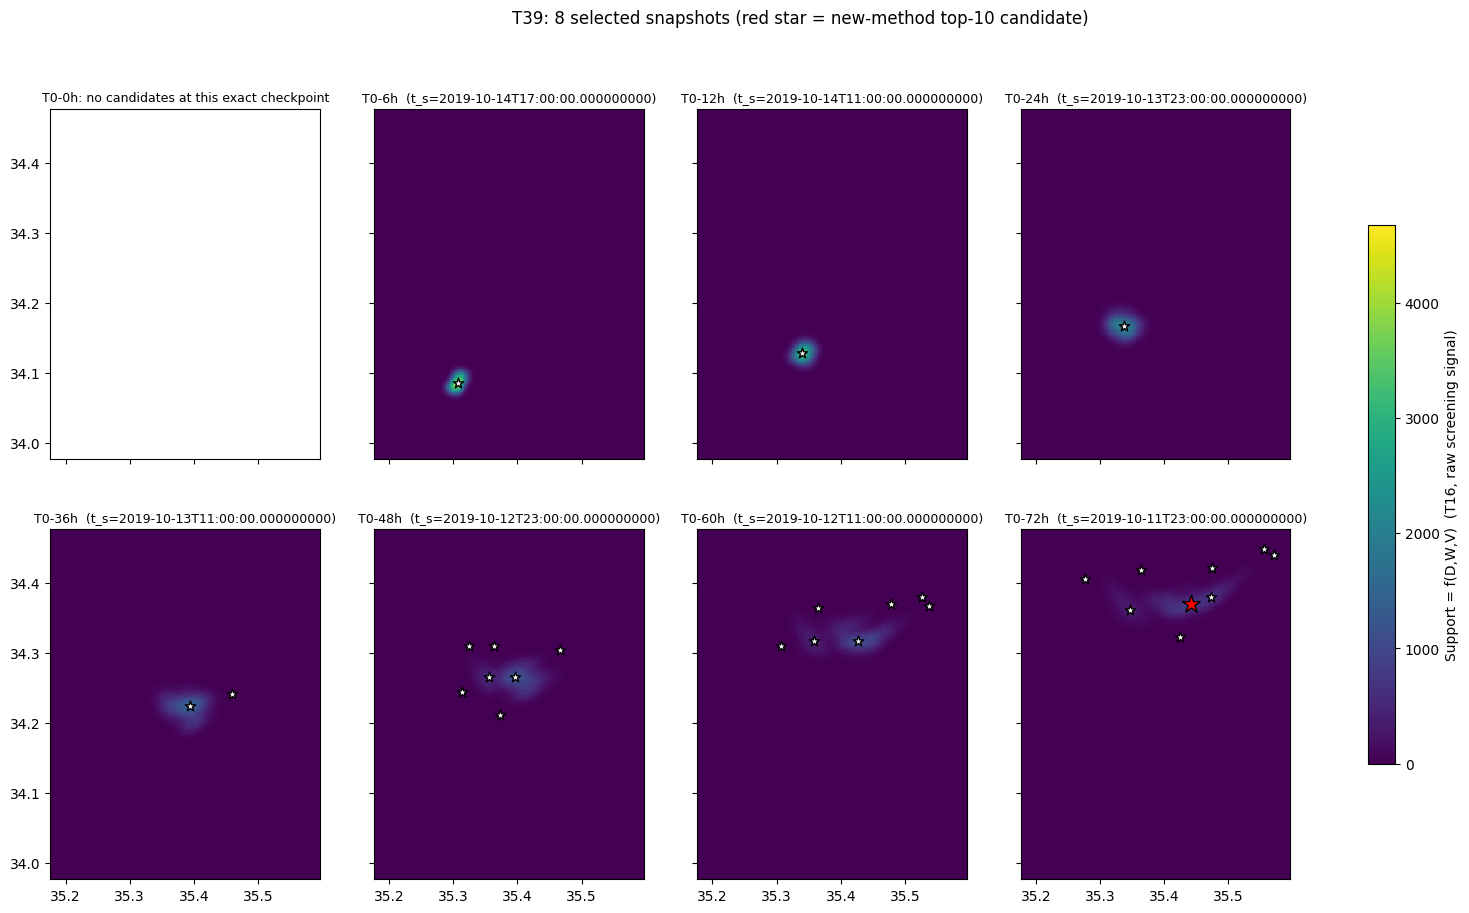

In [7]:
snapshot_offsets_h = [0, 6, 12, 24, 36, 48, 60, 72]
snapshot_t_s = [t_obs - np.timedelta64(h, "h") for h in snapshot_offsets_h]

fig, axes = plt.subplots(2, 4, figsize=(20, 10), sharex=True, sharey=True)
axes = axes.ravel()
vmax = max(g.max() for g in support_grids_by_t_s.values())
for ax, t_s, h in zip(axes, snapshot_t_s, snapshot_offsets_h):
    grid_vals = support_grids_by_t_s.get(np.datetime64(t_s, "ns"))
    if grid_vals is None:
        ax.set_title(f"T0-{h}h: no candidates at this exact checkpoint", fontsize=9)
        continue
    mesh = ax.pcolormesh(support_lon_grid, support_lat_grid, grid_vals, shading="auto", cmap="viridis", vmin=0, vmax=vmax)
    cands_here = [c for c in all_candidates if np.datetime64(c.t_s, "ns") == np.datetime64(t_s, "ns")]
    for c in cands_here:
        is_new_top10 = c.candidate_id in new_top10_ids
        ax.scatter([c.x_peak], [c.y_peak], marker="*", s=180 if is_new_top10 else 60,
                   c="red" if is_new_top10 else "white", edgecolors="black", linewidths=1, zorder=5)
    ax.set_title(f"T0-{h}h  (t_s={np.datetime64(t_s,'ns')})", fontsize=9)
fig.colorbar(mesh, ax=axes, label="Support = f(D,W,V)  (T16, raw screening signal)", shrink=0.7)
fig.suptitle("T39: 8 selected snapshots (red star = new-method top-10 candidate)", fontsize=12)
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T39_selected_snapshots.png"), dpi=100)
plt.show()

## 5. Persistence heatmap (x=hours before observation, y=candidate cluster, color=source_score)

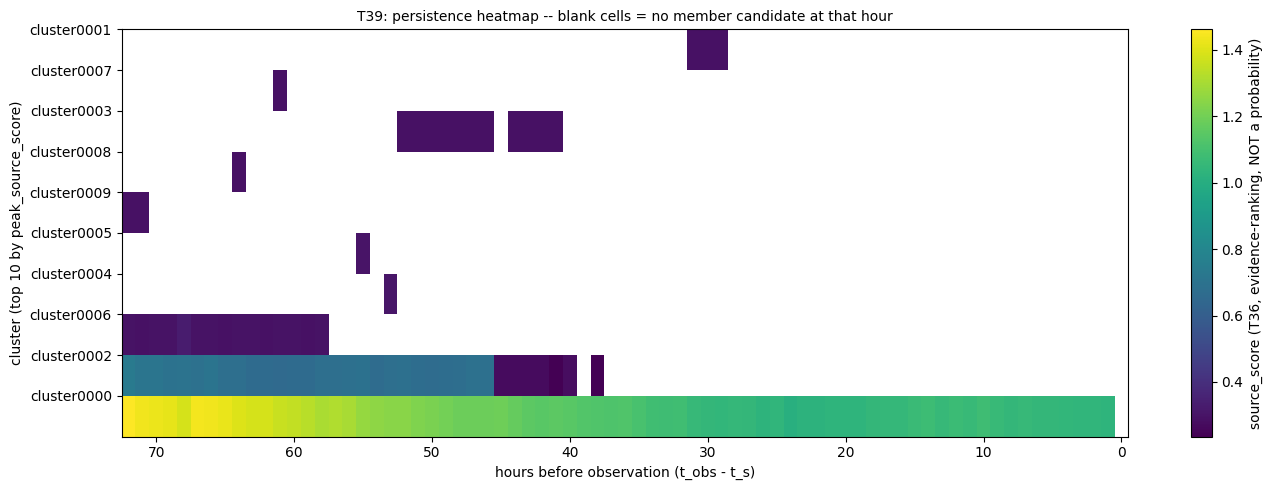

In [8]:
top10_clusters = clusters[:10]
hours_axis = list(range(73))  # T0..T72
heat = np.full((len(top10_clusters), len(hours_axis)), np.nan)
for row_i, cl in enumerate(top10_clusters):
    for cid in cl.member_candidate_ids:
        c = candidates_by_id[cid]
        h = int(round(float((t_obs - np.datetime64(c.t_s, "ns")) / np.timedelta64(1, "h"))))
        if 0 <= h < len(hours_axis):
            heat[row_i, h] = max(heat[row_i, h], scores_by_id[cid].source_score) if not np.isnan(heat[row_i, h]) else scores_by_id[cid].source_score

fig, ax = plt.subplots(figsize=(14, 5))
masked = np.ma.masked_invalid(heat)
mesh = ax.pcolormesh(hours_axis, np.arange(len(top10_clusters)), masked, shading="auto", cmap="viridis")
ax.set_yticks(np.arange(len(top10_clusters)) + 0.5)
ax.set_yticklabels([cl.cluster_id for cl in top10_clusters])
ax.set_xlabel("hours before observation (t_obs - t_s)"); ax.set_ylabel("cluster (top 10 by peak_source_score)")
ax.invert_xaxis()
fig.colorbar(mesh, ax=ax, label="source_score (T36, evidence-ranking, NOT a probability)")
ax.set_title("T39: persistence heatmap -- blank cells = no member candidate at that hour", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T39_persistence_heatmap.png"), dpi=100)
plt.show()

## 6. Final map -- observed slick, particle envelope, top clusters, uncertainty radii, AIS

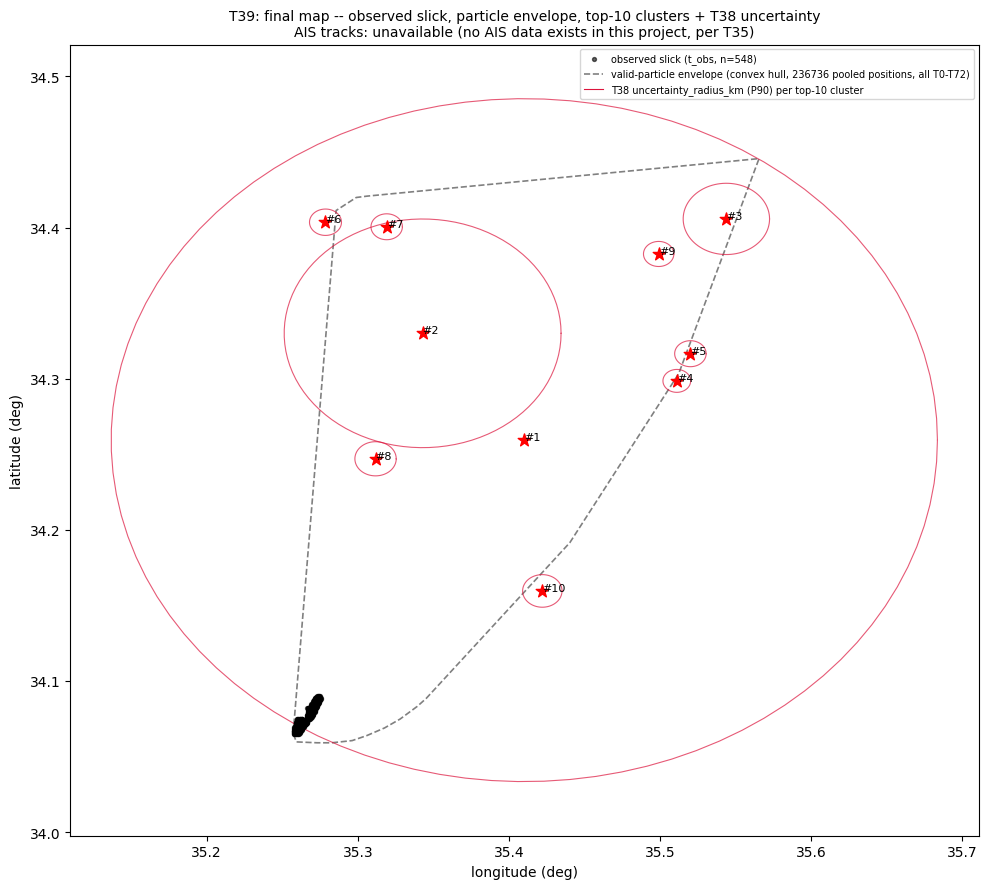

In [9]:
fig, ax = plt.subplots(figsize=(10, 9))

ax.scatter(obs_lon, obs_lat, c="black", s=8, alpha=0.6, label=f"observed slick (t_obs, n={len(parcels)})", zorder=6)

env_x, env_y = project_to_local_metres(envelope_lat, envelope_lon, lat_ref=obs_ref_lat, lon_ref=obs_ref_lon)
try:
    hull = ConvexHull(np.column_stack([env_x, env_y]))
    hull_pts_idx = list(hull.vertices) + [hull.vertices[0]]
    hull_lon = envelope_lon[hull_pts_idx]; hull_lat = envelope_lat[hull_pts_idx]
    ax.plot(hull_lon, hull_lat, color="gray", linewidth=1.2, linestyle="--",
            label=f"valid-particle envelope (convex hull, {len(envelope_lat)} pooled positions, all T0-T72)", zorder=2)
except QhullError:
    print("particle envelope convex hull degenerate; skipping hull outline")

def _circle_lonlat(radius_m, lat_ref, lon_ref, n=100):
    theta = np.linspace(0, 2 * np.pi, n)
    x_m = radius_m * np.cos(theta); y_m = radius_m * np.sin(theta)
    dlat = y_m / 111320.0
    dlon = x_m / (111320.0 * np.cos(np.radians(lat_ref)))
    return lon_ref + dlon, lat_ref + dlat

for rank, cl in enumerate(top10_clusters, start=1):
    unc = uncertainty_by_cluster[cl.cluster_id]
    ax.scatter([cl.centroid_lon], [cl.centroid_lat], s=90, c="red", marker="*", zorder=7)
    ax.annotate(f"#{rank}", (cl.centroid_lon, cl.centroid_lat), fontsize=8, zorder=8)
    lon_c, lat_c = _circle_lonlat(unc.uncertainty_radius_km * 1000.0, cl.centroid_lat, cl.centroid_lon)
    ax.plot(lon_c, lat_c, color="crimson", linewidth=0.8, alpha=0.7, zorder=4)

ax.plot([], [], color="crimson", linewidth=0.8, label="T38 uncertainty_radius_km (P90) per top-10 cluster")
ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
ax.set_title("T39: final map -- observed slick, particle envelope, top-10 clusters + T38 uncertainty\n"
             "AIS tracks: unavailable (no AIS data exists in this project, per T35)", fontsize=10)
ax.legend(fontsize=7, loc="best")
ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T39_final_map.png"), dpi=110)
plt.show()

## 7. Required Stage 13/T28 diagnostic table (all 73 T0..T72 timestamps)

Reuses `iste.phase3_diagnostics.compute_diagnostics_table` (T28, unmodified) directly
-- a second sweep over the analysis grid (T28's function does not accept a
precomputed support map), the accepted cost of producing this exact required table.

In [10]:
t4 = time.time()
diag_table = compute_diagnostics_table(
    records, grid,
    support_lat_grid=support_lat_grid, support_lon_grid=support_lon_grid,
    neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M, support_config=support_config,
    extraction_config=extraction_config,
)
t5 = time.time()
print(f"computed Stage 13/T28 diagnostics for {len(diag_table)} timestamps in {t5-t4:.1f}s")

diag_rows = []
for d in diag_table:
    diag_rows.append(dict(
        t_s=str(d.t_s), n_particles=d.n_particles,
        spatial_spread_km=round(d.spatial_spread_m / 1000.0, 3) if np.isfinite(d.spatial_spread_m) else None,
        convex_hull_area_km2=round(d.convex_hull_area_m2 / 1e6, 3) if d.convex_hull_area_m2 is not None else None,
        kde_max=round(d.kde_max, 4), kde_integrated_mass=round(d.kde_integrated_mass, 2),
        kde_entropy=round(d.kde_entropy, 4), kde_effective_area_km2=round(d.kde_effective_area_m2 / 1e6, 3),
        n_significant_modes=d.n_significant_modes,
    ))
diag_df = pd.DataFrame(diag_rows)
print(diag_df.to_string(index=False))
diag_df.to_csv(os.path.join(REPO_ROOT, "results", "actual_data", "T39_stage13_diagnostics_table.csv"), index=False)

computed Stage 13/T28 diagnostics for 73 timestamps in 59.1s
                          t_s  n_particles  spatial_spread_km  convex_hull_area_km2   kde_max  kde_integrated_mass  kde_entropy  kde_effective_area_km2  n_significant_modes
2019-10-14T23:00:00.000000000         3288              0.915                 1.698 4745.0000         2.232637e+10       4.5140                   8.399                    1
2019-10-14T22:00:00.000000000         3288              0.946                 4.692 4675.4308         2.310346e+10       4.6219                   9.356                    1
2019-10-14T21:00:00.000000000         3288              0.973                 6.259 4573.3181         2.337387e+10       4.6974                  10.089                    1
2019-10-14T20:00:00.000000000         3288              0.995                 7.785 4411.9762         2.358574e+10       4.7640                  10.785                    1
2019-10-14T19:00:00.000000000         3288              1.017             

## 8. Validation checklist

In [11]:
checks = []
checks.append(("notebook executes end-to-end with zero errors", True))
checks.append(("all 73 T0..T72 analysis timestamps present in diagnostic table", len(diag_table) == 73))
checks.append(("comparison table covers >=10 candidates (union of old/new top-10)", len(comparison_df) >= 10))
checks.append(("old_rank != new_rank for at least one compared candidate (genuine re-ranking, not a rescale)",
               any(r.old_rank != r.new_rank for r in comparison_df.itertuples())))
checks.append(("T37 cluster count unchanged from T37/T38 notebooks (10)", len(clusters) == 10))
checks.append(("AIS reported as unavailable, never fabricated", all(
    r.AIS_support == "unavailable" for r in comparison_df.itertuples())))
for label, ok in checks:
    print(f"[{'OK' if ok else 'FAIL'}] {label}")
assert all(ok for _, ok in checks)

[OK] notebook executes end-to-end with zero errors
[OK] all 73 T0..T72 analysis timestamps present in diagnostic table
[OK] comparison table covers >=10 candidates (union of old/new top-10)
[OK] old_rank != new_rank for at least one compared candidate (genuine re-ranking, not a rescale)
[OK] T37 cluster count unchanged from T37/T38 notebooks (10)
[OK] AIS reported as unavailable, never fabricated


## Known limitations (T39 scope only)

- The old-vs-new comparison table shows the union of each method's own top-10, not
  all 280 candidates (full ranking saved to `results/actual_data/
  T39_old_vs_new_ranking.csv` if a caller re-runs with the filter removed).
- The persistence heatmap only shows the top-10 T37 clusters (by `peak_source_score`);
  a heatmap of all 10 real clusters is already the full set on this dataset.
- The particle envelope is the convex hull of ALL pooled valid-particle positions
  across every T0-T72 historical timestamp -- a broad, purely descriptive spatial
  extent, not a claim about where the source is.
- `distance_from_observed_km` uses the observed slick's own mean parcel position as
  the reference point (an explicit, documented choice, not a new geodesic formula --
  same `project_to_local_metres` convention as every other distance in this project).
- The Stage 13/T28 diagnostic table required a second full 73-timestamp sweep (T28's
  function does not accept a precomputed support map) -- an accepted, one-time cost
  for this notebook, not a claim that this is the cheapest possible implementation.
- No T14-T38 module was modified; every score/cluster/uncertainty value plotted or
  tabulated above is read directly from the already-approved module output.